First five rows:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB

Missing values:
CustomerID            

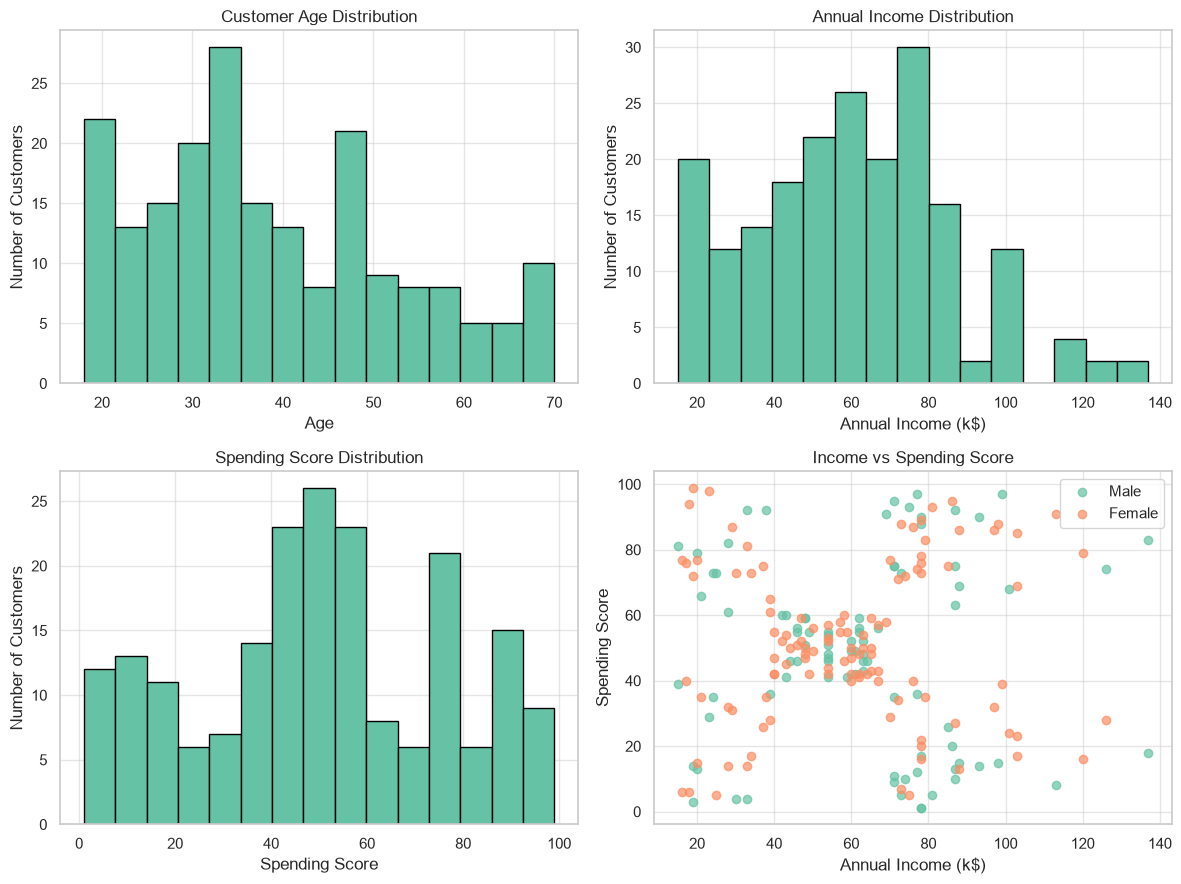

   Number of Clusters (K)  Inertia  Silhouette Score
0                       2  588.803             0.252
1                       3  476.788             0.260
2                       4  388.718             0.298
3                       5  331.310             0.304
4                       6  276.412             0.331
5                       7  236.205             0.357
6                       8  199.750             0.388
7                       9  174.235             0.403
8                      10  152.030             0.421


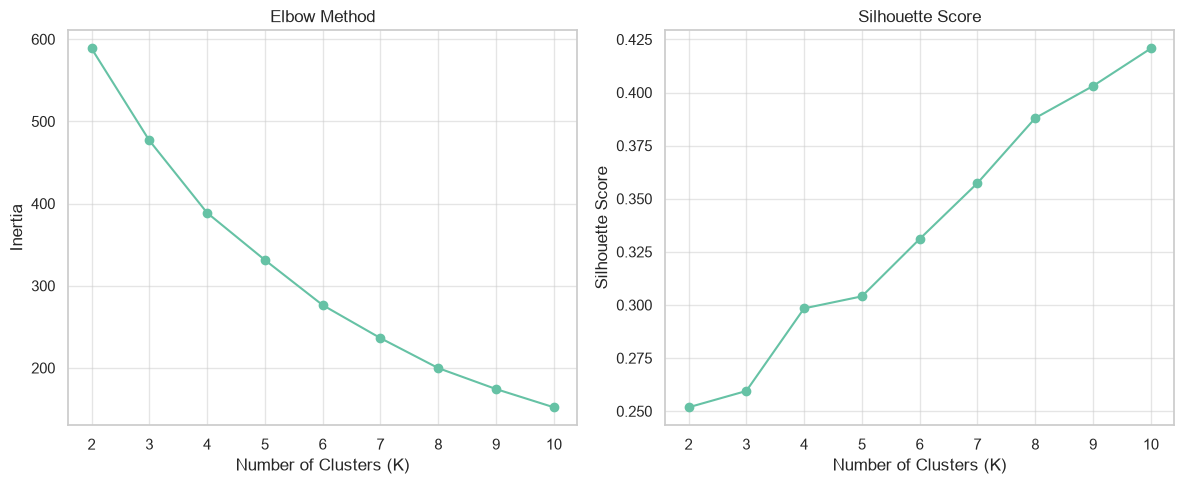

           Age  Annual Income (k$)  Spending Score (1-100)  \
Cluster                                                      
0        32.69               86.54                   82.13   
1        36.48               89.52                   18.00   
2        49.81               49.23                   40.07   
3        24.91               39.72                   61.20   
4        55.71               53.69                   36.77   

         Number of Customers  
Cluster                       
0                         39  
1                         29  
2                         43  
3                         54  
4                         35  


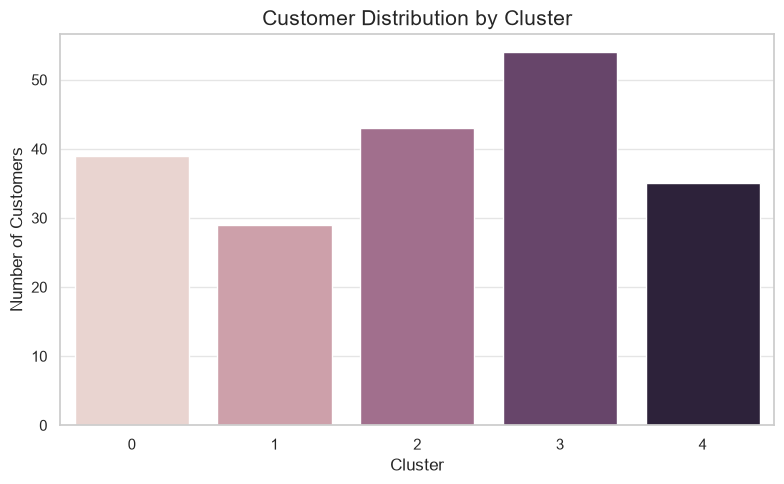

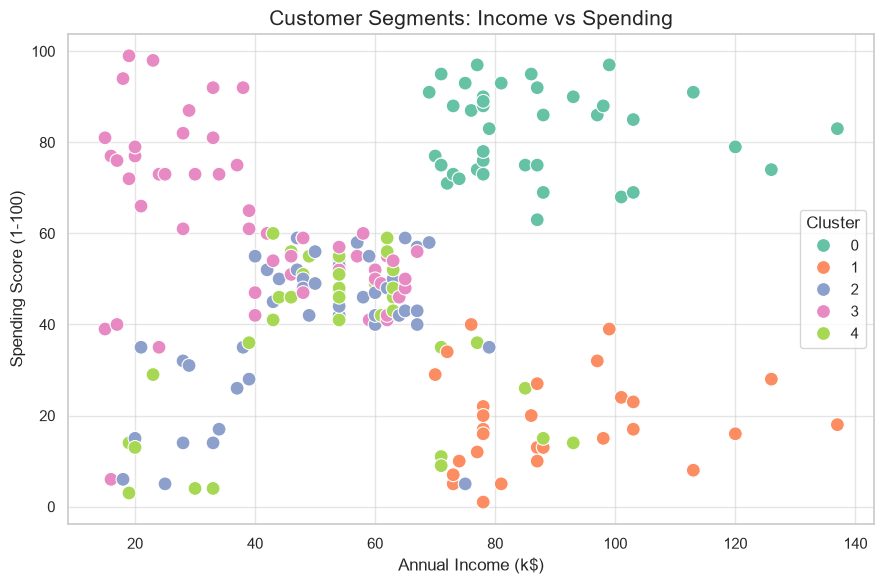

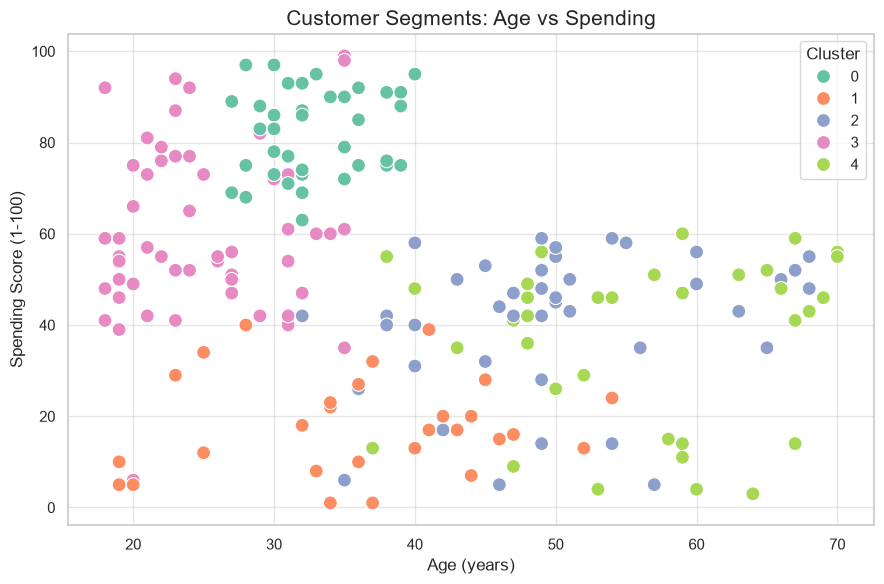

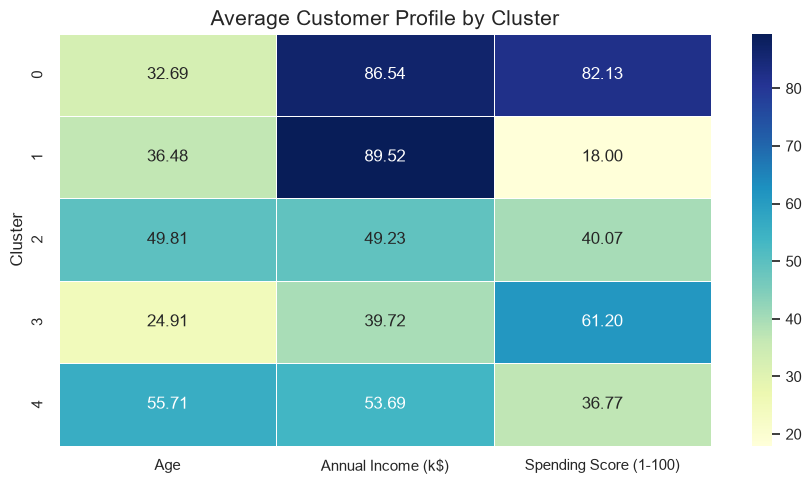

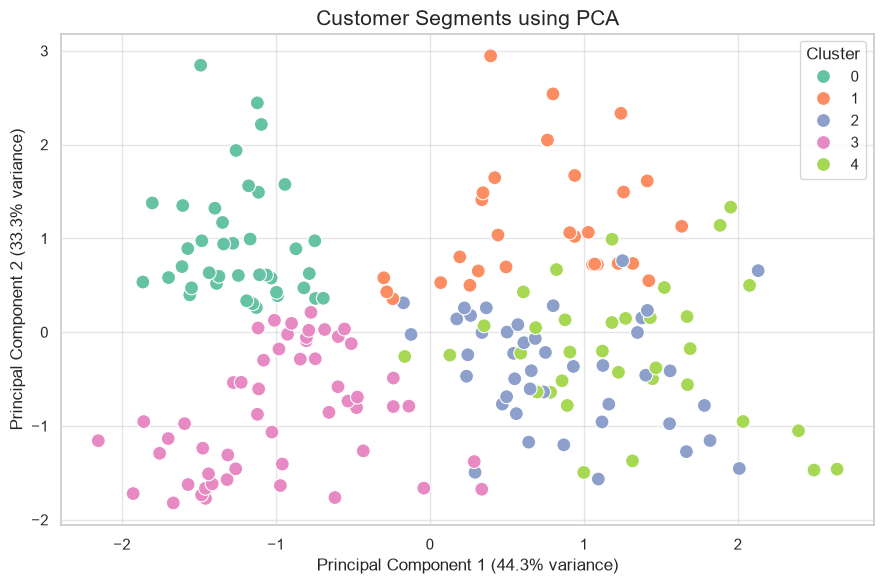

CUSTOMER SEGMENT PROFILES


,Age,Annual Income (k$),Spending Score (1-100),Customer Count,Customer Percentage
Cluster,,,,,
0,32.69,86.54,82.13,39,19.5
1,36.48,89.52,18.00,29,14.5
2,49.81,49.23,40.07,43,21.5
3,24.91,39.72,61.20,54,27.0
4,55.71,53.69,36.77,35,17.5



SEGMENT INTERPRETATION


Cluster 0
----------------------------------------
Customers: 39
Average age: 32.69
Average income: $86.54k
Average spending score: 82.13
Income group: High income
Spending group: High spending
Age group: Relatively young customers
Business strategy: Offer premium products, loyalty rewards, VIP services, and personalized recommendations.

Cluster 1
----------------------------------------
Customers: 29
Average age: 36.48
Average income: $89.52k
Average spending score: 18.00
Income group: High income
Spending group: Low spending
Age group: Middle-range age group
Business strategy: Use personalized promotions, exclusive product previews, and targeted campaigns to encourage purchases.

Cluster 2
----------------------------------------
Customers: 43
Average age: 49.81
Average income: $49.23k
Average spending score: 40.07
Income group: Low income
Spending group: Low spending
Age group: Relatively older customers
Business strategy: Use budget-friendly offers, intro

In [19]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import seaborn as sns

# 1. Load dataset
df = pd.read_csv("Mall_Customers.csv")
##  STEP 2:
# 2. Check dataset
print("First five rows:")
print(df.head())

print("\nDataset information:")
df.info()

# 3. Handle missing values
print("\nMissing values:")
print(df.isnull().sum())

# Fill missing numerical values with median
for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with mode
for col in df.select_dtypes(include=["object", "str"]).columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

# 4. Remove duplicate records
print("\nDuplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

# 5. Remove irrelevant column
df = df.drop(columns=["CustomerID"])

# 6. Encode categorical variable
df["Gender"] = df["Gender"].map({
    "Male": 0,
    "Female": 1
})

# 7. Normalize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# Convert normalized data into DataFrame
X_scaled = pd.DataFrame(
    X_scaled,
    columns=df.columns
)

# 8. Display preprocessed dataset
print("\nPreprocessed Dataset:")
print(X_scaled.head())
##  STEP 3:
print("\nFinal Dataset Shape:", X_scaled.shape)
# 1. Load original dataset for EDA
eda_df = pd.read_csv("Mall_Customers.csv")

# 2. Statistical summary
print("Statistical Summary:")
print(eda_df[[
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]].describe().round(2))

# 3. Gender distribution
print("\nGender Distribution:")
print(eda_df["Gender"].value_counts())

# 4. Average customer characteristics by gender
print("\nAverage Features by Gender:")
print(
    eda_df.groupby("Gender")[
        ["Age", "Annual Income (k$)",
         "Spending Score (1-100)"]
    ].mean().round(2)
)

# 5. Check correlations between numerical features
print("\nCorrelation Matrix:")
numeric_cols = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]
print(eda_df[numeric_cols].corr().round(2))

# 6. Visualizations
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Age distribution
axes[0, 0].hist(eda_df["Age"], bins=15, edgecolor="black")
axes[0, 0].set_title("Customer Age Distribution")
axes[0, 0].set_xlabel("Age")
axes[0, 0].set_ylabel("Number of Customers")

# Annual income distribution
axes[0, 1].hist(
    eda_df["Annual Income (k$)"],
    bins=15,
    edgecolor="black"
)
axes[0, 1].set_title("Annual Income Distribution")
axes[0, 1].set_xlabel("Annual Income (k$)")
axes[0, 1].set_ylabel("Number of Customers")

# Spending score distribution
axes[1, 0].hist(
    eda_df["Spending Score (1-100)"],
    bins=15,
    edgecolor="black"
)
axes[1, 0].set_title("Spending Score Distribution")
axes[1, 0].set_xlabel("Spending Score")
axes[1, 0].set_ylabel("Number of Customers")

# Income vs spending score
for gender in eda_df["Gender"].unique():
    subset = eda_df[eda_df["Gender"] == gender]
    axes[1, 1].scatter(
        subset["Annual Income (k$)"],
        subset["Spending Score (1-100)"],
        label=gender,
        alpha=0.7
    )

axes[1, 1].set_title("Income vs Spending Score")
axes[1, 1].set_xlabel("Annual Income (k$)")
axes[1, 1].set_ylabel("Spending Score")
axes[1, 1].legend()

plt.tight_layout()
plt.show()
##  STEP 4:
# Use the scaled dataset from Step 2
inertia_values = []
silhouette_scores = []
k_values = range(2, 11)

# Test different numbers of clusters
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    inertia_values.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

# Display scores
results = pd.DataFrame({
    "Number of Clusters (K)": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_scores
})

print(results.round(3))

# Plot both evaluation methods
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(list(k_values), inertia_values, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(list(k_values))

axes[1].plot(list(k_values), silhouette_scores, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(list(k_values))

plt.tight_layout()
plt.show()
optimal_k = 5

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

cluster_summary = df.groupby("Cluster").agg({
    "Age": "mean",
    "Annual Income (k$)": "mean",
    "Spending Score (1-100)": "mean",
    "Gender": "count"
}).round(2)

cluster_summary = cluster_summary.rename(
    columns={"Gender": "Number of Customers"}
)

print(cluster_summary)
##  STEP 5:
# Professional chart style
sns.set_theme(style="whitegrid", palette="Set2")

features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

# 1. Cluster Distribution Chart
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Cluster", hue="Cluster", legend=False)

plt.title("Customer Distribution by Cluster", fontsize=15)
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("01_cluster_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

# 2. Annual Income vs Spending Score
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="Set2",
    s=100
)

plt.title("Customer Segments: Income vs Spending", fontsize=15)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.savefig("02_income_vs_spending.png", dpi=300, bbox_inches="tight")
plt.show()

# 3. Age vs Spending Score
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Age",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="Set2",
    s=100
)

plt.title("Customer Segments: Age vs Spending", fontsize=15)
plt.xlabel("Age (years)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.savefig("03_age_vs_spending.png", dpi=300, bbox_inches="tight")
plt.show()


# 4. Cluster Profile Heatmap
cluster_profile = df.groupby("Cluster")[features].mean()

plt.figure(figsize=(9, 5))

sns.heatmap(
    cluster_profile,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Average Customer Profile by Cluster", fontsize=15)
plt.tight_layout()
plt.savefig("04_cluster_profile_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()


# 5. PCA Visualization
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = df[features]

# Standardize features before PCA
X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": df["Cluster"].values
})

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set2",
    s=100
)

plt.title("Customer Segments using PCA", fontsize=15)
plt.xlabel(
    f"Principal Component 1 "
    f"({pca.explained_variance_ratio_[0] * 100:.1f}% variance)"
)
plt.ylabel(
    f"Principal Component 2 "
    f"({pca.explained_variance_ratio_[1] * 100:.1f}% variance)"
)
plt.legend(title="Cluster")
plt.tight_layout()
plt.savefig("05_pca_visualization.png", dpi=300, bbox_inches="tight")
plt.show()
##  STEP 6:
# Features used for customer segmentation
features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

# Calculate average profile of each cluster
cluster_profile = df.groupby("Cluster")[features].mean().round(2)

# Count customers in each cluster
cluster_profile["Customer Count"] = df.groupby("Cluster").size()

# Calculate the percentage of total customers
cluster_profile["Customer Percentage"] = (
    cluster_profile["Customer Count"] / len(df) * 100
).round(2)

print("CUSTOMER SEGMENT PROFILES")
display(cluster_profile)

# Compare each cluster against overall average
overall_income = df["Annual Income (k$)"].mean()
overall_spending = df["Spending Score (1-100)"].mean()
overall_age = df["Age"].mean()

print("\nSEGMENT INTERPRETATION\n")

for cluster, row in cluster_profile.iterrows():

    income = row["Annual Income (k$)"]
    spending = row["Spending Score (1-100)"]
    age = row["Age"]
    count = int(row["Customer Count"])

    # Income interpretation
    if income >= overall_income * 1.10:
        income_label = "High income"
    elif income <= overall_income * 0.90:
        income_label = "Low income"
    else:
        income_label = "Average income"

    # Spending interpretation
    if spending >= overall_spending * 1.15:
        spending_label = "High spending"
    elif spending <= overall_spending * 0.85:
        spending_label = "Low spending"
    else:
        spending_label = "Average spending"

    # Age interpretation
    if age < overall_age - 5:
        age_label = "Relatively young customers"
    elif age > overall_age + 5:
        age_label = "Relatively older customers"
    else:
        age_label = "Middle-range age group"

    print(f"\nCluster {cluster}")
    print("-" * 40)
    print(f"Customers: {count}")
    print(f"Average age: {age:.2f}")
    print(f"Average income: ${income:.2f}k")
    print(f"Average spending score: {spending:.2f}")
    print(f"Income group: {income_label}")
    print(f"Spending group: {spending_label}")
    print(f"Age group: {age_label}")

    # Business recommendations
    if income_label == "High income" and spending_label == "High spending":
        strategy = (
            "Offer premium products, loyalty rewards, VIP services, "
            "and personalized recommendations."
        )
    elif income_label == "High income" and spending_label == "Low spending":
        strategy = (
            "Use personalized promotions, exclusive product previews, "
            "and targeted campaigns to encourage purchases."
        )
    elif income_label == "Low income" and spending_label == "High spending":
        strategy = (
            "Offer affordable premium options, bundles, reward points, "
            "and relevant discounts."
        )
    elif income_label == "Low income" and spending_label == "Low spending":
        strategy = (
            "Use budget-friendly offers, introductory discounts, "
            "and customer engagement campaigns."
        )
    elif spending_label == "High spending":
        strategy = (
            "Recommend complementary products, loyalty programs, "
            "and personalized marketing."
        )
    elif spending_label == "Low spending":
        strategy = (
            "Use relevant promotions, customer feedback, and "
            "re-engagement campaigns."
        )
    else:
        strategy = (
            "Use product recommendations, seasonal campaigns, "
            "and loyalty incentives to improve engagement."
        )

    print("Business strategy:", strategy)


